# 📊 BÀI TOÁN BENCHMARK MÔ HÌNH AI: ĐÁNH GIÁ THỰC NGHIỆM VÀ KIỂM ĐỊNH THỐNG KÊ
### **Môn học:** Thống kê máy tính và ứng dụng (Computational Statistics & Applications)
**Tác giả:** Trần Hoàng Anh (MSSV: 24684541)  
**Mục tiêu:** Áp dụng các phương pháp Thống kê suy diễn (Inferential Statistics), Mô phỏng máy tính (Computational Statistics / Bootstrap) và Kiểm định giả thuyết (Hypothesis Testing) để đánh giá, so sánh khoa học hiệu năng của 3 kiến trúc mô hình Trí tuệ Nhân tạo.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm đường dẫn src
sys.path.insert(0, os.path.abspath(".."))

from src.data_loader import load_or_create_dataset
from src.models import AIModelBenchmarkSuite
from src.statistical_tests import (
    bootstrap_metrics,
    perform_mcnemar_test,
    cross_validate_and_test,
    analyze_latency_distributions
)
from src.visualizer import (
    plot_forest_plot,
    plot_mcnemar_heatmap,
    plot_cv_boxplots,
    plot_latency_distributions,
    plot_roc_curves
)

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
print("✅ Đã nạp thành công các thư viện Thống kê và Học máy!")


✅ Đã nạp thành công các thư viện Thống kê và Học máy!


## 1. Khám Phá Dữ Liệu Thực Nghiệm (Exploratory Data Analysis - EDA)
Tập dữ liệu Benchmark Corpus mô phỏng $N = 3,000$ phản hồi khách hàng sàn thương mại điện tử với 2 lớp nhãn cảm xúc:
- **0**: Tiêu cực (Negative)
- **1**: Tích cực (Positive)

Dữ liệu được phân chia theo tỷ lệ phân tầng (Stratified Splitting): **70% Train, 10% Validation, 20% Test**.


In [2]:
train_df, val_df, test_df = load_or_create_dataset(data_dir="../data")

X_train, y_train = train_df["clean_text"].tolist(), train_df["label"].values
X_test, y_test = test_df["clean_text"].tolist(), test_df["label"].values

print(f"Kích thước Train: {len(X_train)} quan sát")
print(f"Kích thước Test:  {len(X_test)} quan sát")

# Thống kê mô tả độ dài câu
train_df["word_count"] = train_df["clean_text"].apply(lambda s: len(s.split()))
print("\nThống kê mô tả số lượng từ trong văn bản:")
display(train_df["word_count"].describe().to_frame().T)


[DataLoader] Đã tải dữ liệu sẵn có: Train=2100, Val=300, Test=600
Kích thước Train: 2100 quan sát
Kích thước Test:  600 quan sát

Thống kê mô tả số lượng từ trong văn bản:


,count,mean,std,min,25%,50%,75%,max
word_count,2100.0,20.381429,3.66248,12.0,18.0,20.5,23.0,28.0


## 2. Huấn Luyện 3 Mô Hình AI Đại Diện (Three Paradigms)
1. **Model A (Statistical Linear Model):** Logistic Regression với TF-IDF N-grams (1, 2)
2. **Model B (Ensemble Tree Model):** Random Forest Classifier (150 cây, max_depth=25)
3. **Model C (Deep Learning Representation):** Multi-Layer Perceptron (Tầng ẩn: 128, 64)


In [3]:
suite = AIModelBenchmarkSuite(random_state=42)
suite.train_all(X_train, y_train)

eval_results = suite.evaluate_all(X_test, y_test)


[ModelSuite] Bắt đầu huấn luyện các mô hình...
 -> Đã huấn luyện xong: Logistic Regression       (Thời gian: 0.10s)


 -> Đã huấn luyện xong: Random Forest             (Thời gian: 1.52s)


 -> Đã huấn luyện xong: Multi-Layer Perceptron    (Thời gian: 0.85s)
[ModelSuite] Logistic Regression       | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9509 | Mean Latency: 2.34ms


[ModelSuite] Random Forest             | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9522 | Mean Latency: 24.36ms


[ModelSuite] Multi-Layer Perceptron    | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9498 | Mean Latency: 2.36ms


## 3. Mô Phỏng Máy Tính: Ước Lượng Khoảng Tin Cậy 95% Bootstrap (Bootstrap CI)
Trong thống kê máy tính, khi không biết rõ phân phối chuẩn của các độ đo phức tạp như F1-Score, phương pháp **Empirical Bootstrap** với $B = 2,000$ vòng lặp tái lấy mẫu có hoàn lại (sampling with replacement) cho phép ước lượng sai số chuẩn $SE_{boot}$ và khoảng tin cậy 95% theo phân vị $[q_{0.025}, q_{0.975}]$.


In [4]:
bootstrap_results = {}
summary_table = []

for name, res in eval_results.items():
    boot_res = bootstrap_metrics(y_test, res["y_pred"], res["y_prob"], n_bootstraps=2000, random_state=42)
    bootstrap_results[name] = boot_res
    
    acc_info = boot_res["accuracy"]
    f1_info = boot_res["f1_score"]
    auc_info = boot_res["roc_auc"]
    
    summary_table.append({
        "Model": name,
        "Accuracy (Point Est.)": f"{acc_info['point_estimate']:.4f}",
        "Accuracy (95% CI)": f"[{acc_info['ci_95_lower']:.4f}, {acc_info['ci_95_upper']:.4f}]",
        "F1-Score (Point Est.)": f"{f1_info['point_estimate']:.4f}",
        "F1-Score (95% CI)": f"[{f1_info['ci_95_lower']:.4f}, {f1_info['ci_95_upper']:.4f}]",
        "ROC-AUC (95% CI)": f"[{auc_info['ci_95_lower']:.4f}, {auc_info['ci_95_upper']:.4f}]",
        "Mean Latency (ms)": f"{np.mean(res['latencies_ms']):.2f}"
    })

df_metrics = pd.DataFrame(summary_table)
display(df_metrics)


,Model,Accuracy (Point Est.),Accuracy (95% CI),F1-Score (Point Est.),F1-Score (95% CI),ROC-AUC (95% CI),Mean Latency (ms)
0,Logistic Regression,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9277, 0.9698]",2.34
1,Random Forest,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9313, 0.9712]",24.36
2,Multi-Layer Perceptron,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9288, 0.9683]",2.36


[Visualizer] Đã lưu Forest Plot: ../results/figures/forest_plot_ci.png


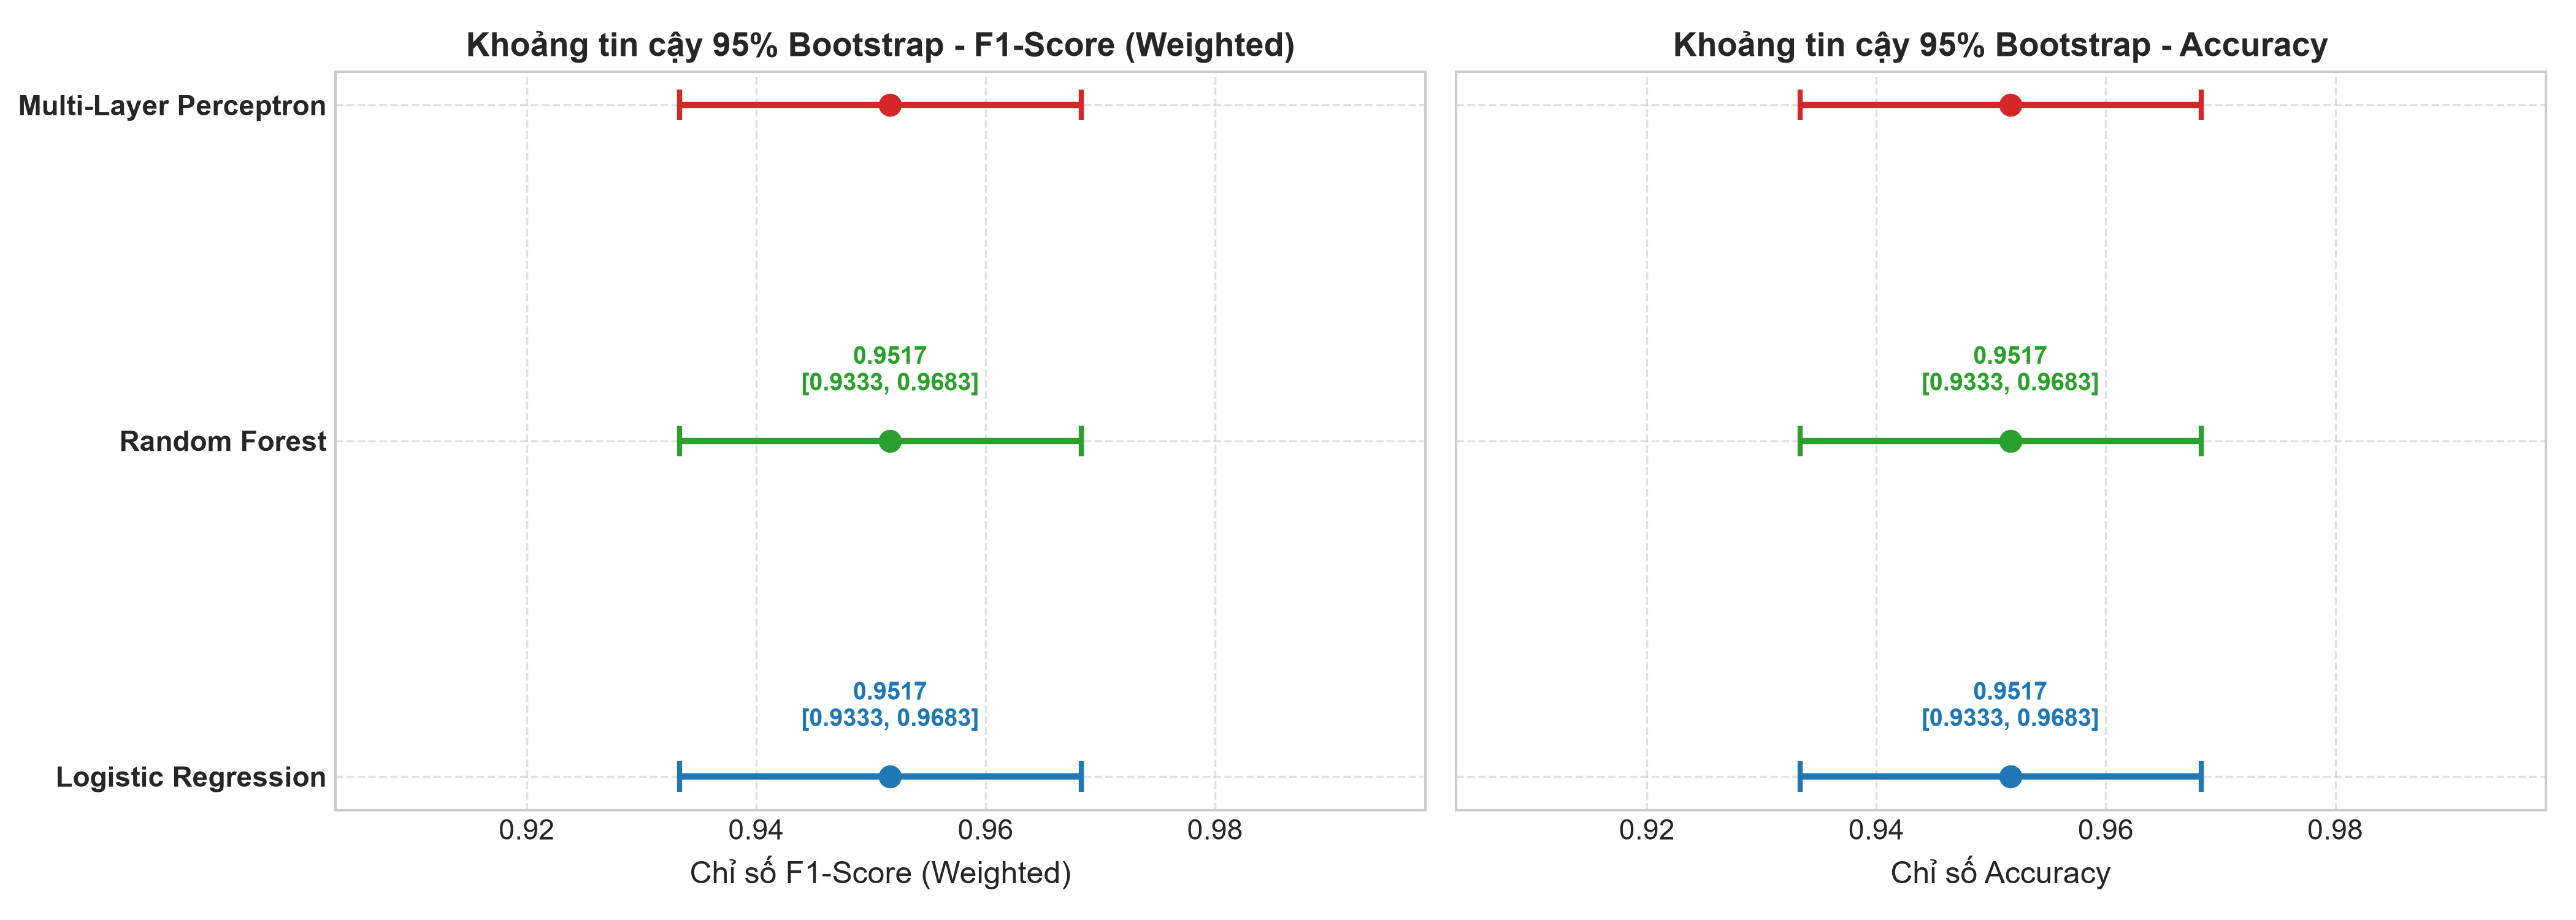

In [5]:
# Trực quan hóa Forest Plot thể hiện khoảng tin cậy 95%
plot_forest_plot(bootstrap_results, output_path="../results/figures/forest_plot_ci.png")
from IPython.display import Image
Image(filename="../results/figures/forest_plot_ci.png")


## 4. Kiểm Định Giả Thuyết McNemar (McNemar's Test)
So sánh hai mô hình phân loại trên cùng tập dữ liệu kiểm tra.
- **Giả thuyết $H_0$:** $p_{01} = p_{10}$ (Tỷ lệ phân loại sai cận biên của hai mô hình là tương đương nhau).
- **Giả thuyết đối $H_1$:** $p_{01} 
eq p_{10}$ (Hai mô hình có sự khác biệt có ý nghĩa thống kê về hiệu năng phân loại sai).
- **Tiêu chuẩn kiểm định (Edwards Continuity Correction):**
$$\chi^2 = \frac{(|n_{01} - n_{10}| - 1)^2}{n_{01} + n_{10}} \sim \chi^2(1)$$


[Visualizer] Đã lưu McNemar Heatmap: ../results/figures/mcnemar_contingency.png


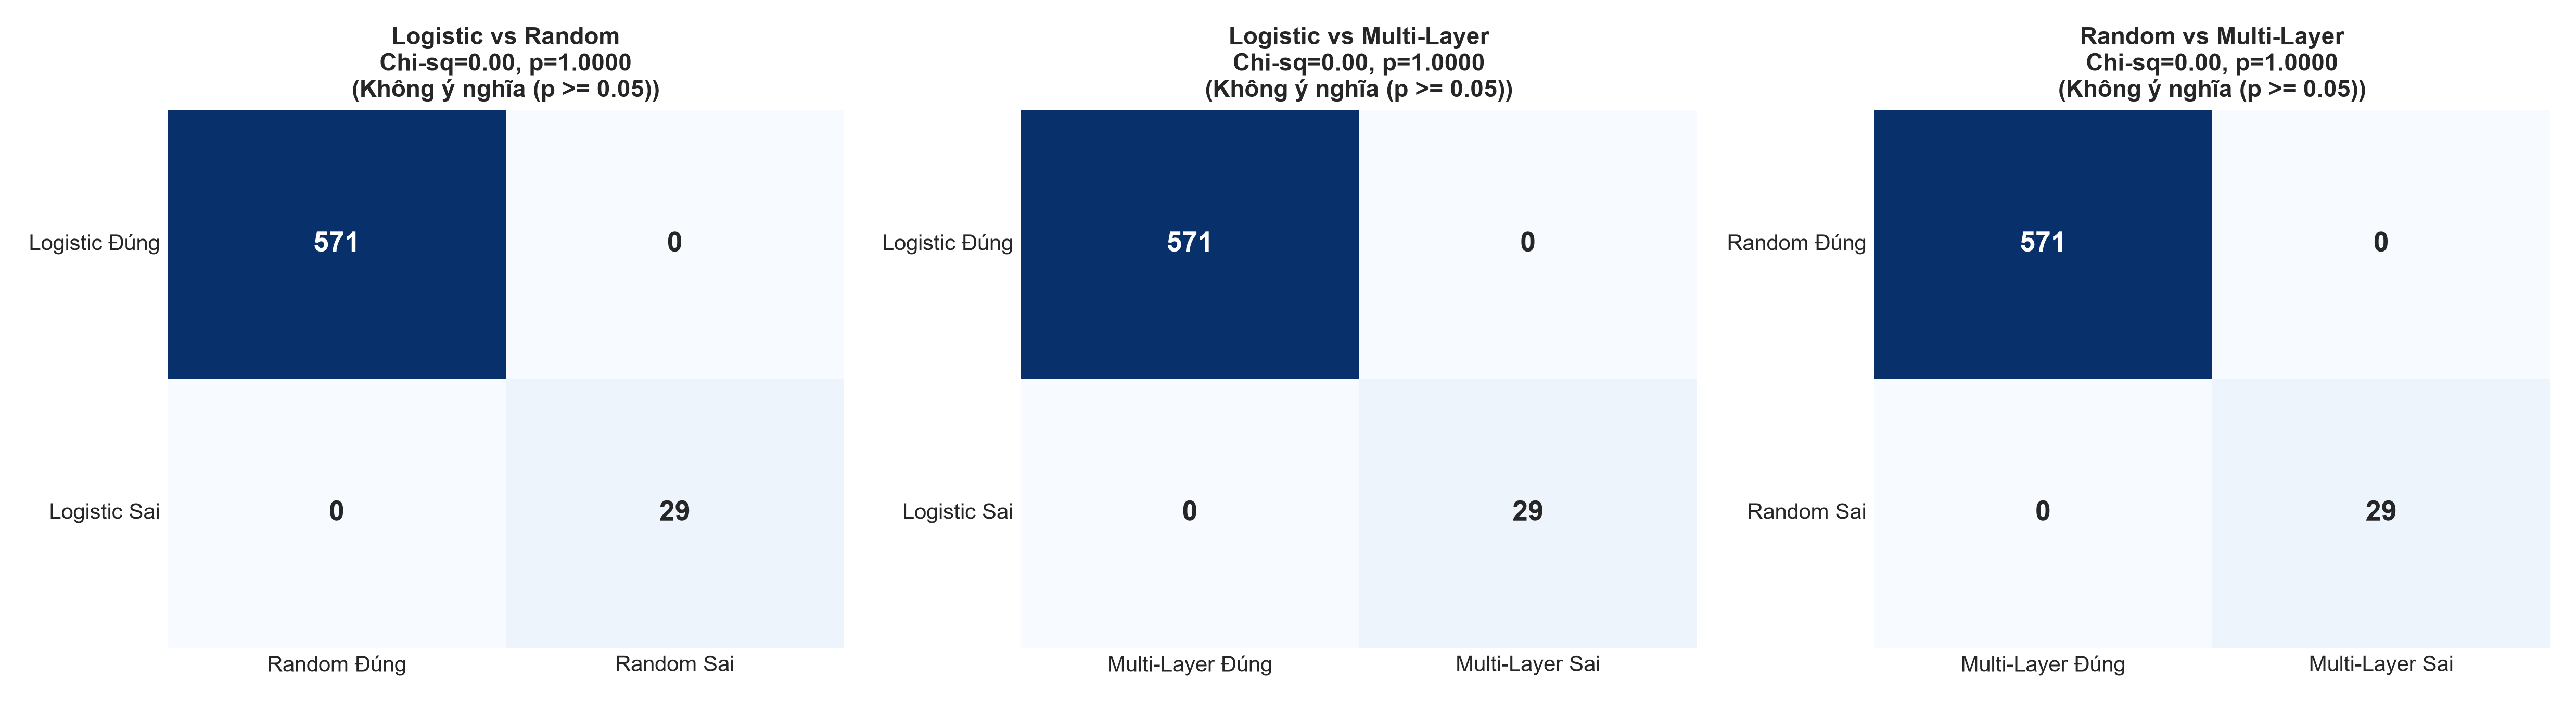

In [6]:
mcnemar_list = []
model_names = list(eval_results.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        mA, mB = model_names[i], model_names[j]
        res = perform_mcnemar_test(y_test, eval_results[mA]["y_pred"], eval_results[mB]["y_pred"], mA, mB)
        mcnemar_list.append(res)

plot_mcnemar_heatmap(mcnemar_list, output_path="../results/figures/mcnemar_contingency.png")
Image(filename="../results/figures/mcnemar_contingency.png")


## 5. 10-Fold Cross-Validation: Kiểm Định Cặp & Repeated Measures ANOVA
Đánh giá độ ổn định của các mô hình trên 10 phân vùng mẫu (Folds).
1. Kiểm tra tính phân phối chuẩn của hiệu số điểm $d_i = F1_{A,i} - F1_{B,i}$ bằng **Shapiro-Wilk Test**.
2. Nếu thỏa mãn phân phối chuẩn ($p > 0.05$): Áp dụng **Paired Student's t-test**.
3. Nếu vi phạm phân phối chuẩn ($p \le 0.05$): Áp dụng **Wilcoxon Signed-Rank Test**.
4. Thực hiện **Repeated Measures ANOVA** để kiểm định sự khác biệt tổng thể giữa cả 3 mô hình.


[CV-Test] Đang thực hiện 10-Fold Stratified Cross-Validation...


C:\Users\Shark\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


Repeated Measures ANOVA: F = 0.3013, p-value = 7.4231e-01


,pair,mean_diff,shapiro_normality_p,assumption_normal,test_used,statistic,p_value,is_significant_05
0,Logistic Regression vs Random Forest,0.002332,0.0006,False,Wilcoxon Signed-Rank Test,0.0,0.125,False
1,Logistic Regression vs Multi-Layer Perceptron,0.000000,1.0000,True,Paired Student's t-test,NaN,NaN,False
2,Random Forest vs Multi-Layer Perceptron,-0.002332,0.0006,False,Wilcoxon Signed-Rank Test,0.0,0.125,False


D:\Data\Project git\Statistical_AI_Benchmarking\src\visualizer.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Model", y="F1-Score", data=df_cv, palette=palette, width=0.45,


[Visualizer] Đã lưu CV Boxplots: ../results/figures/cv_scores_comparison.png


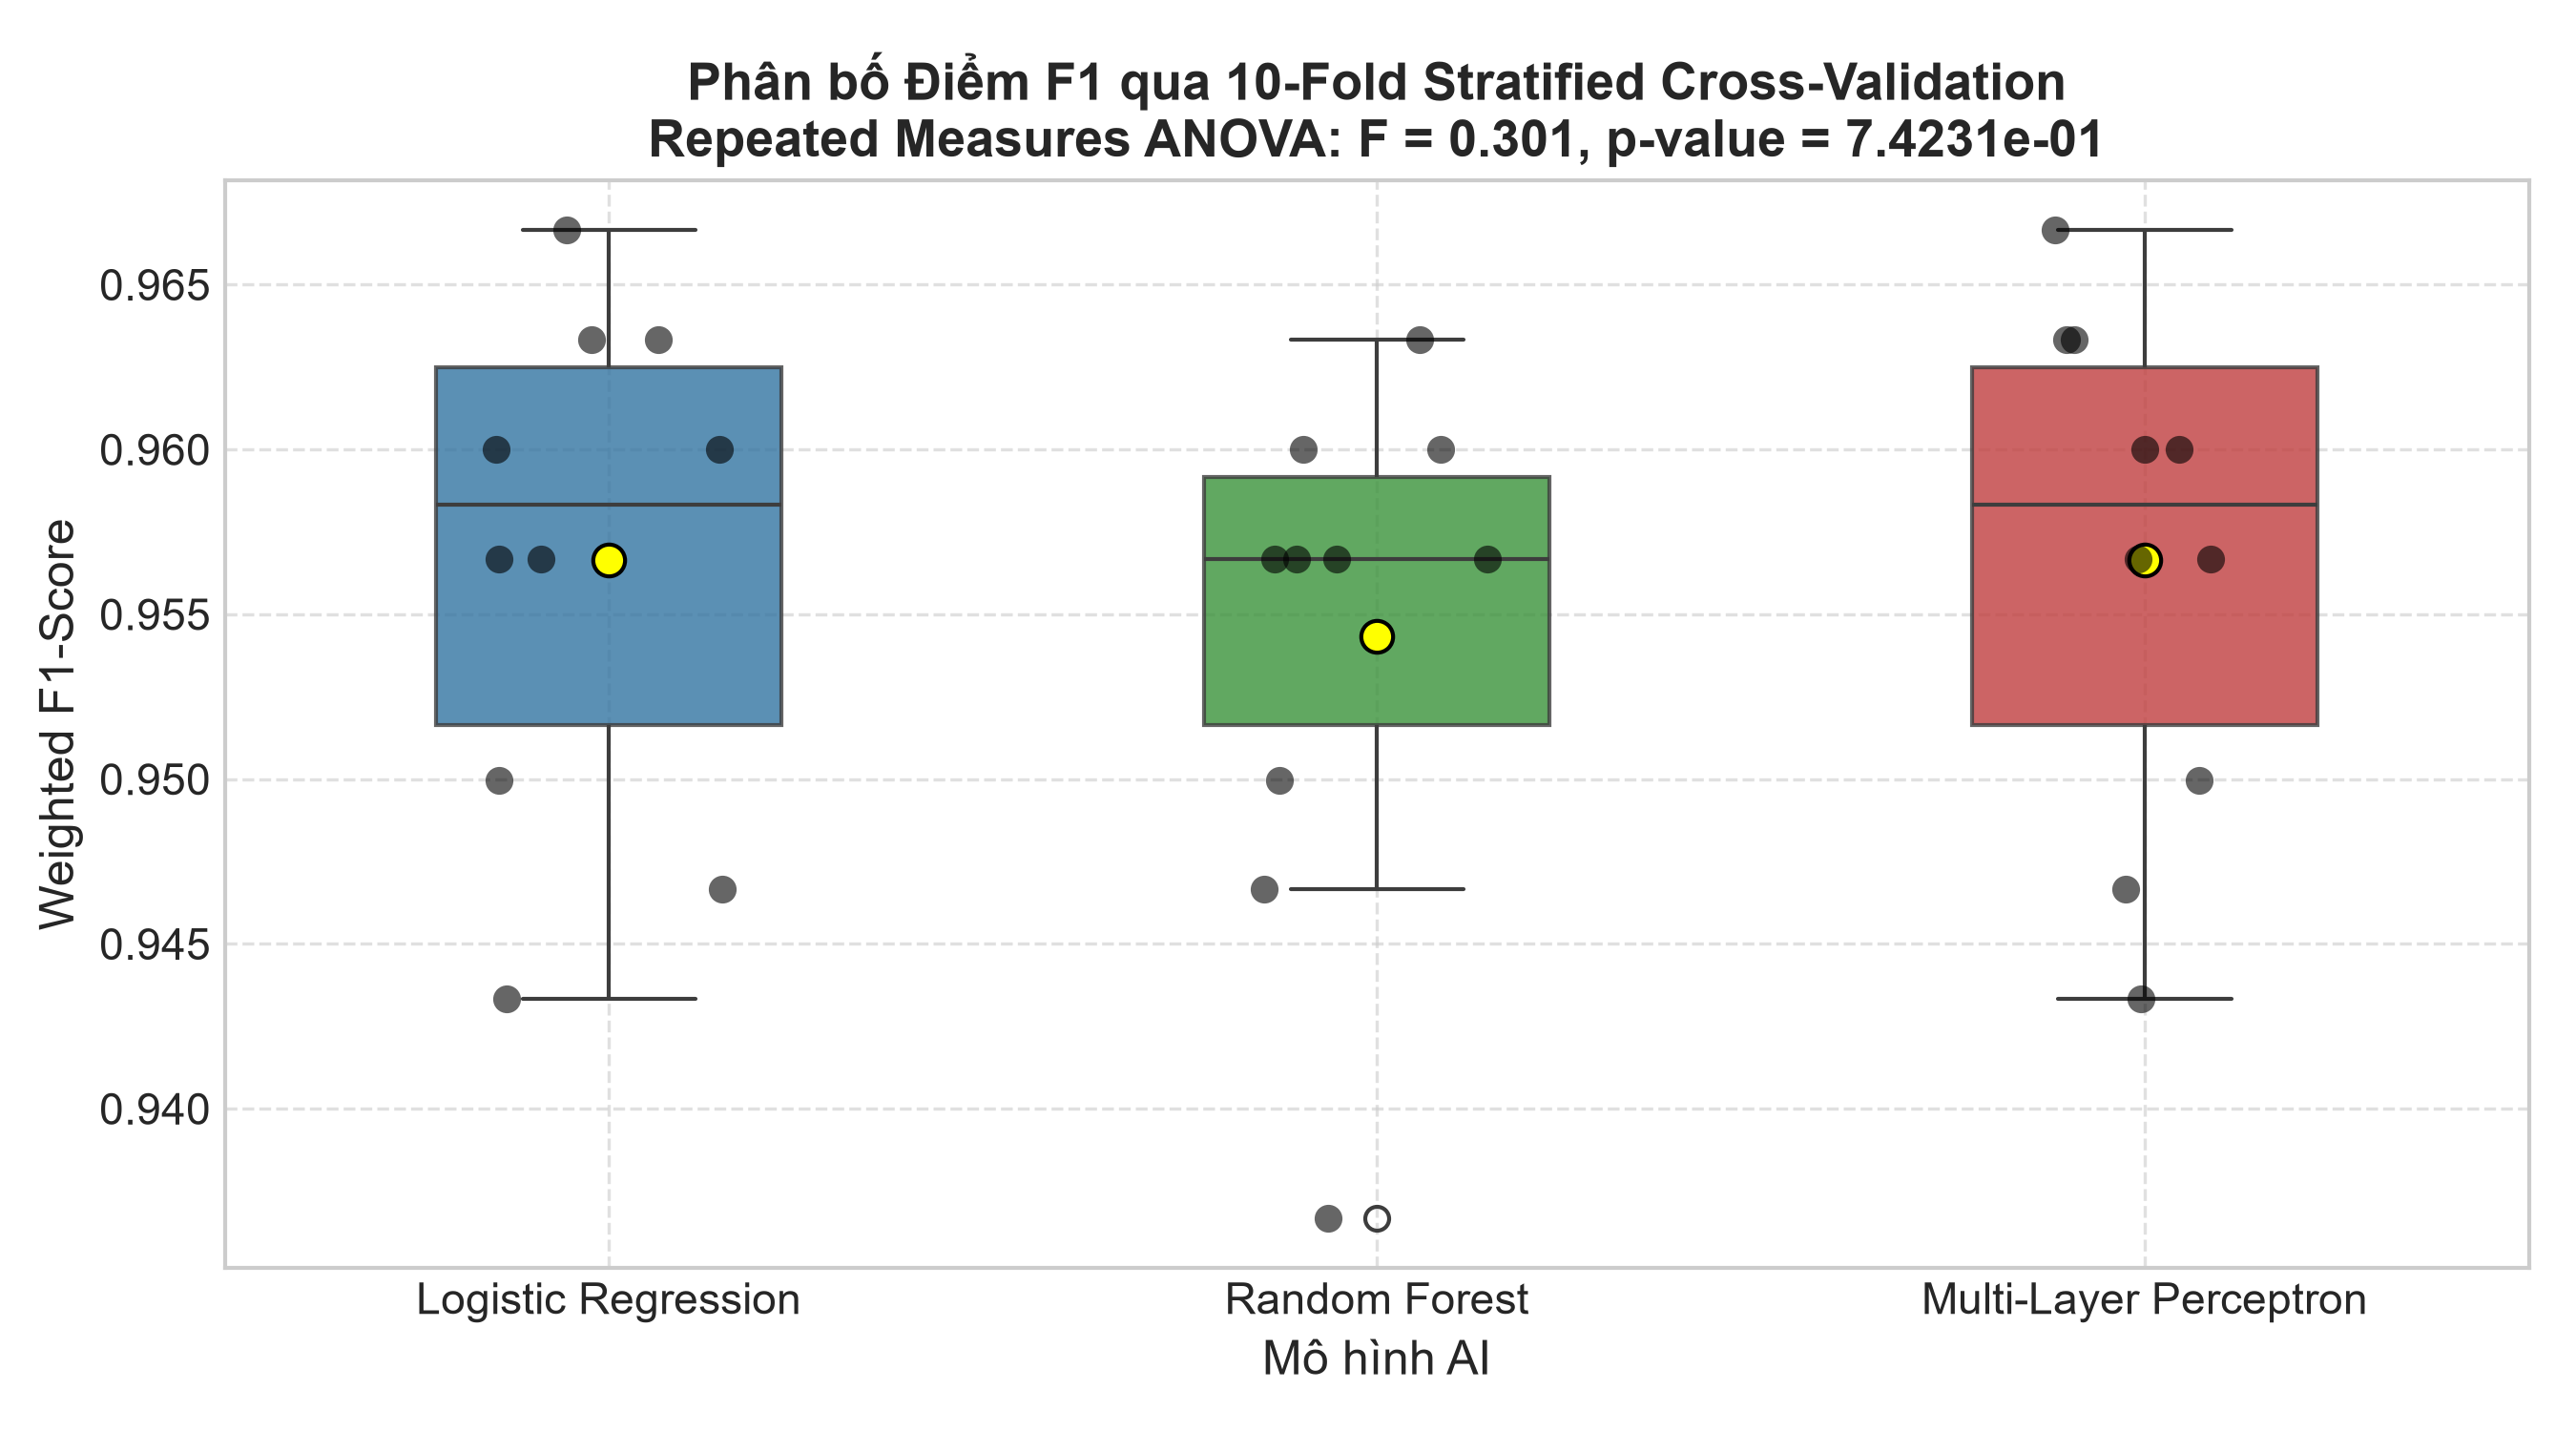

In [7]:
full_X = train_df["clean_text"].tolist() + val_df["clean_text"].tolist() + test_df["clean_text"].tolist()
full_y = np.concatenate([y_train, val_df["label"].values, y_test])

cv_results = cross_validate_and_test(suite.models, full_X, full_y, k_folds=10, random_state=42)

# Hiển thị kết quả ANOVA
anova = cv_results["anova"]
print(f"Repeated Measures ANOVA: F = {anova['f_statistic']:.4f}, p-value = {anova['p_value']:.4e}")

# Hiển thị kết quả kiểm định cặp
display(pd.DataFrame(cv_results["pairwise_tests"]))

# Vẽ biểu đồ Boxplot
plot_cv_boxplots(cv_results, output_path="../results/figures/cv_scores_comparison.png")
Image(filename="../results/figures/cv_scores_comparison.png")


## 6. Phân Tích Thống Kê Độ Trễ Suy Luận (Inference Latency)
Phân tích thời gian suy luận (Inference Latency tính theo ms) trên từng mẫu để phục vụ bài toán triển khai thực tế (Production Deployment).
- Kiểm tra phân phối đuôi dài Log-Normal qua **Kolmogorov-Smirnov Test**.
- Thống kê các mốc bách phân vị quan trọng: **Trung vị, P95, P99 Latency**.
- Kiểm định phi tham số **Mann-Whitney U Test** để so sánh tốc độ giữa các mô hình.


Thống kê chi tiết độ trễ suy luận (ms):


,mean_ms,std_ms,median_ms,iqr_ms,p95_ms,p99_ms,lognormal_ks_statistic,lognormal_ks_pvalue
Logistic Regression,2.343519,0.275329,2.22640,0.385025,2.862290,3.209618,0.165888,6.719909e-15
Random Forest,24.361804,1.385463,24.03125,1.339675,26.300325,31.148149,0.106531,2.201815e-06
Multi-Layer Perceptron,2.356338,0.302337,2.24590,0.384675,2.998725,3.200001,0.152257,1.308276e-12



Kiểm định Mann-Whitney U về tốc độ:


,pair,u_statistic,p_value,is_significant_05,faster_model,speedup_ratio
0,Logistic Regression vs Random Forest,0.0,1.431530e-197,True,Logistic Regression,10.793770
1,Logistic Regression vs Multi-Layer Perceptron,181197.0,8.420017e-01,False,Logistic Regression,1.008759
2,Random Forest vs Multi-Layer Perceptron,360000.0,1.431508e-197,True,Multi-Layer Perceptron,10.700053


[Visualizer] Đã lưu Latency Distribution: ../results/figures/latency_distribution.png


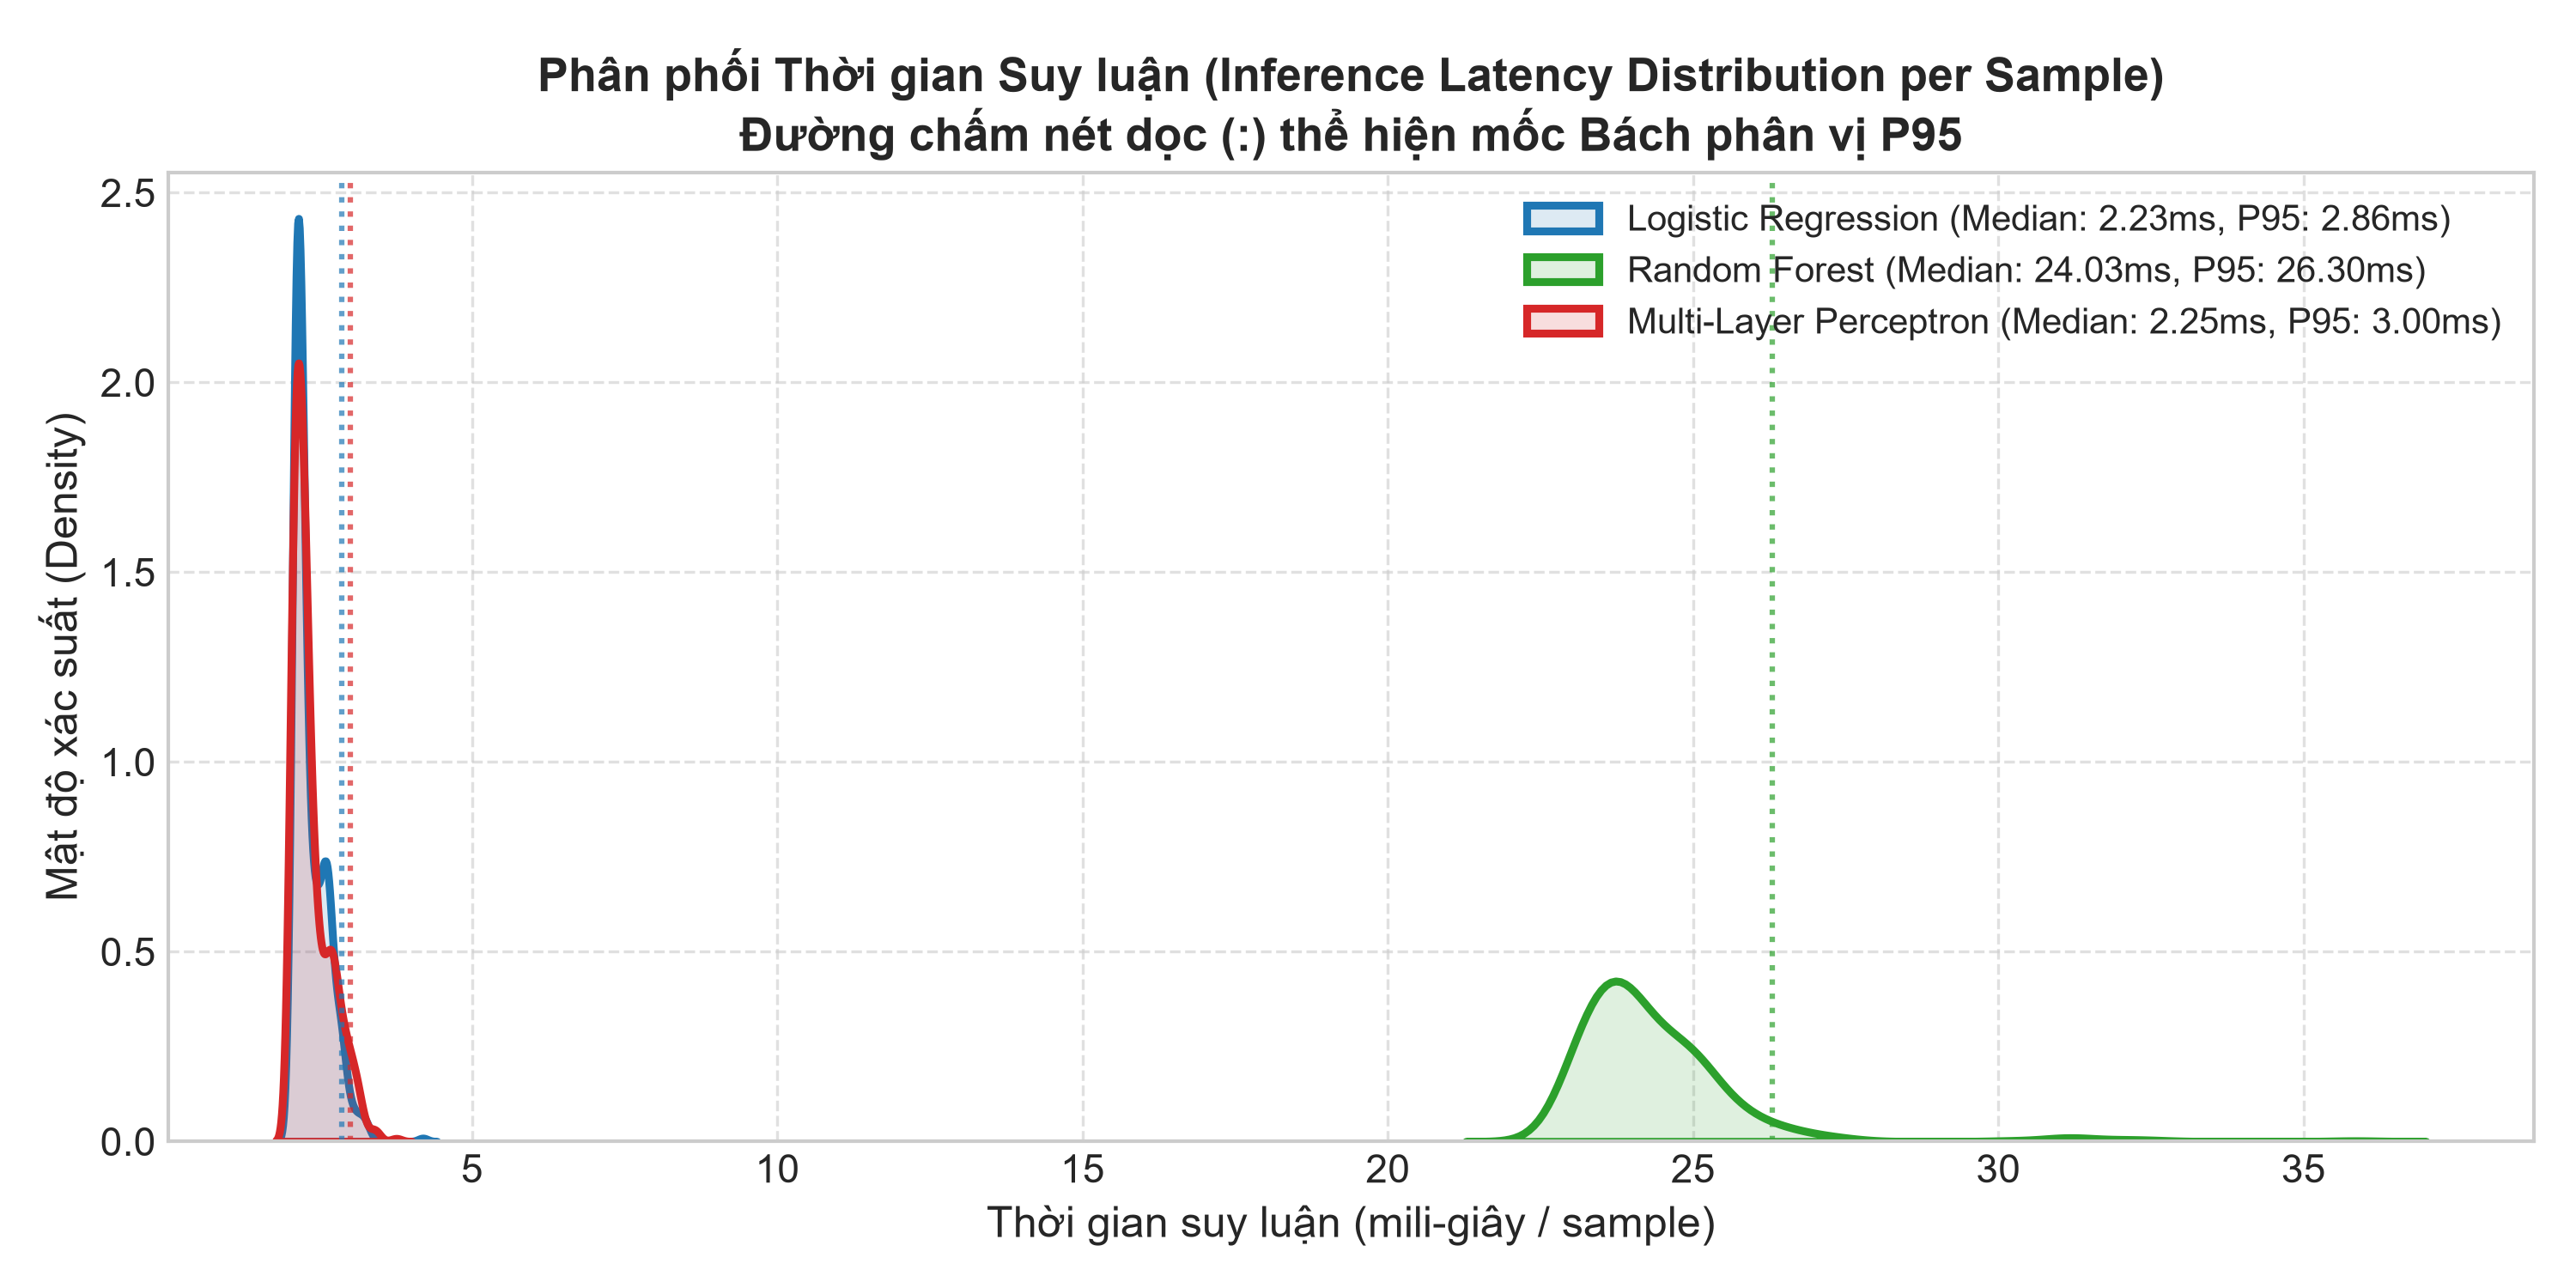

In [8]:
latencies_dict = {name: eval_results[name]["latencies_ms"] for name in model_names}
latency_stats = analyze_latency_distributions(latencies_dict)

print("Thống kê chi tiết độ trễ suy luận (ms):")
display(pd.DataFrame(latency_stats["summary_statistics"]).T)

print("\nKiểm định Mann-Whitney U về tốc độ:")
display(pd.DataFrame(latency_stats["pairwise_latency_tests"]))

# Vẽ biểu đồ phân phối độ trễ
plot_latency_distributions(latencies_dict, latency_stats, output_path="../results/figures/latency_distribution.png")
Image(filename="../results/figures/latency_distribution.png")


[Visualizer] Đã lưu ROC Curves: ../results/figures/roc_curves.png


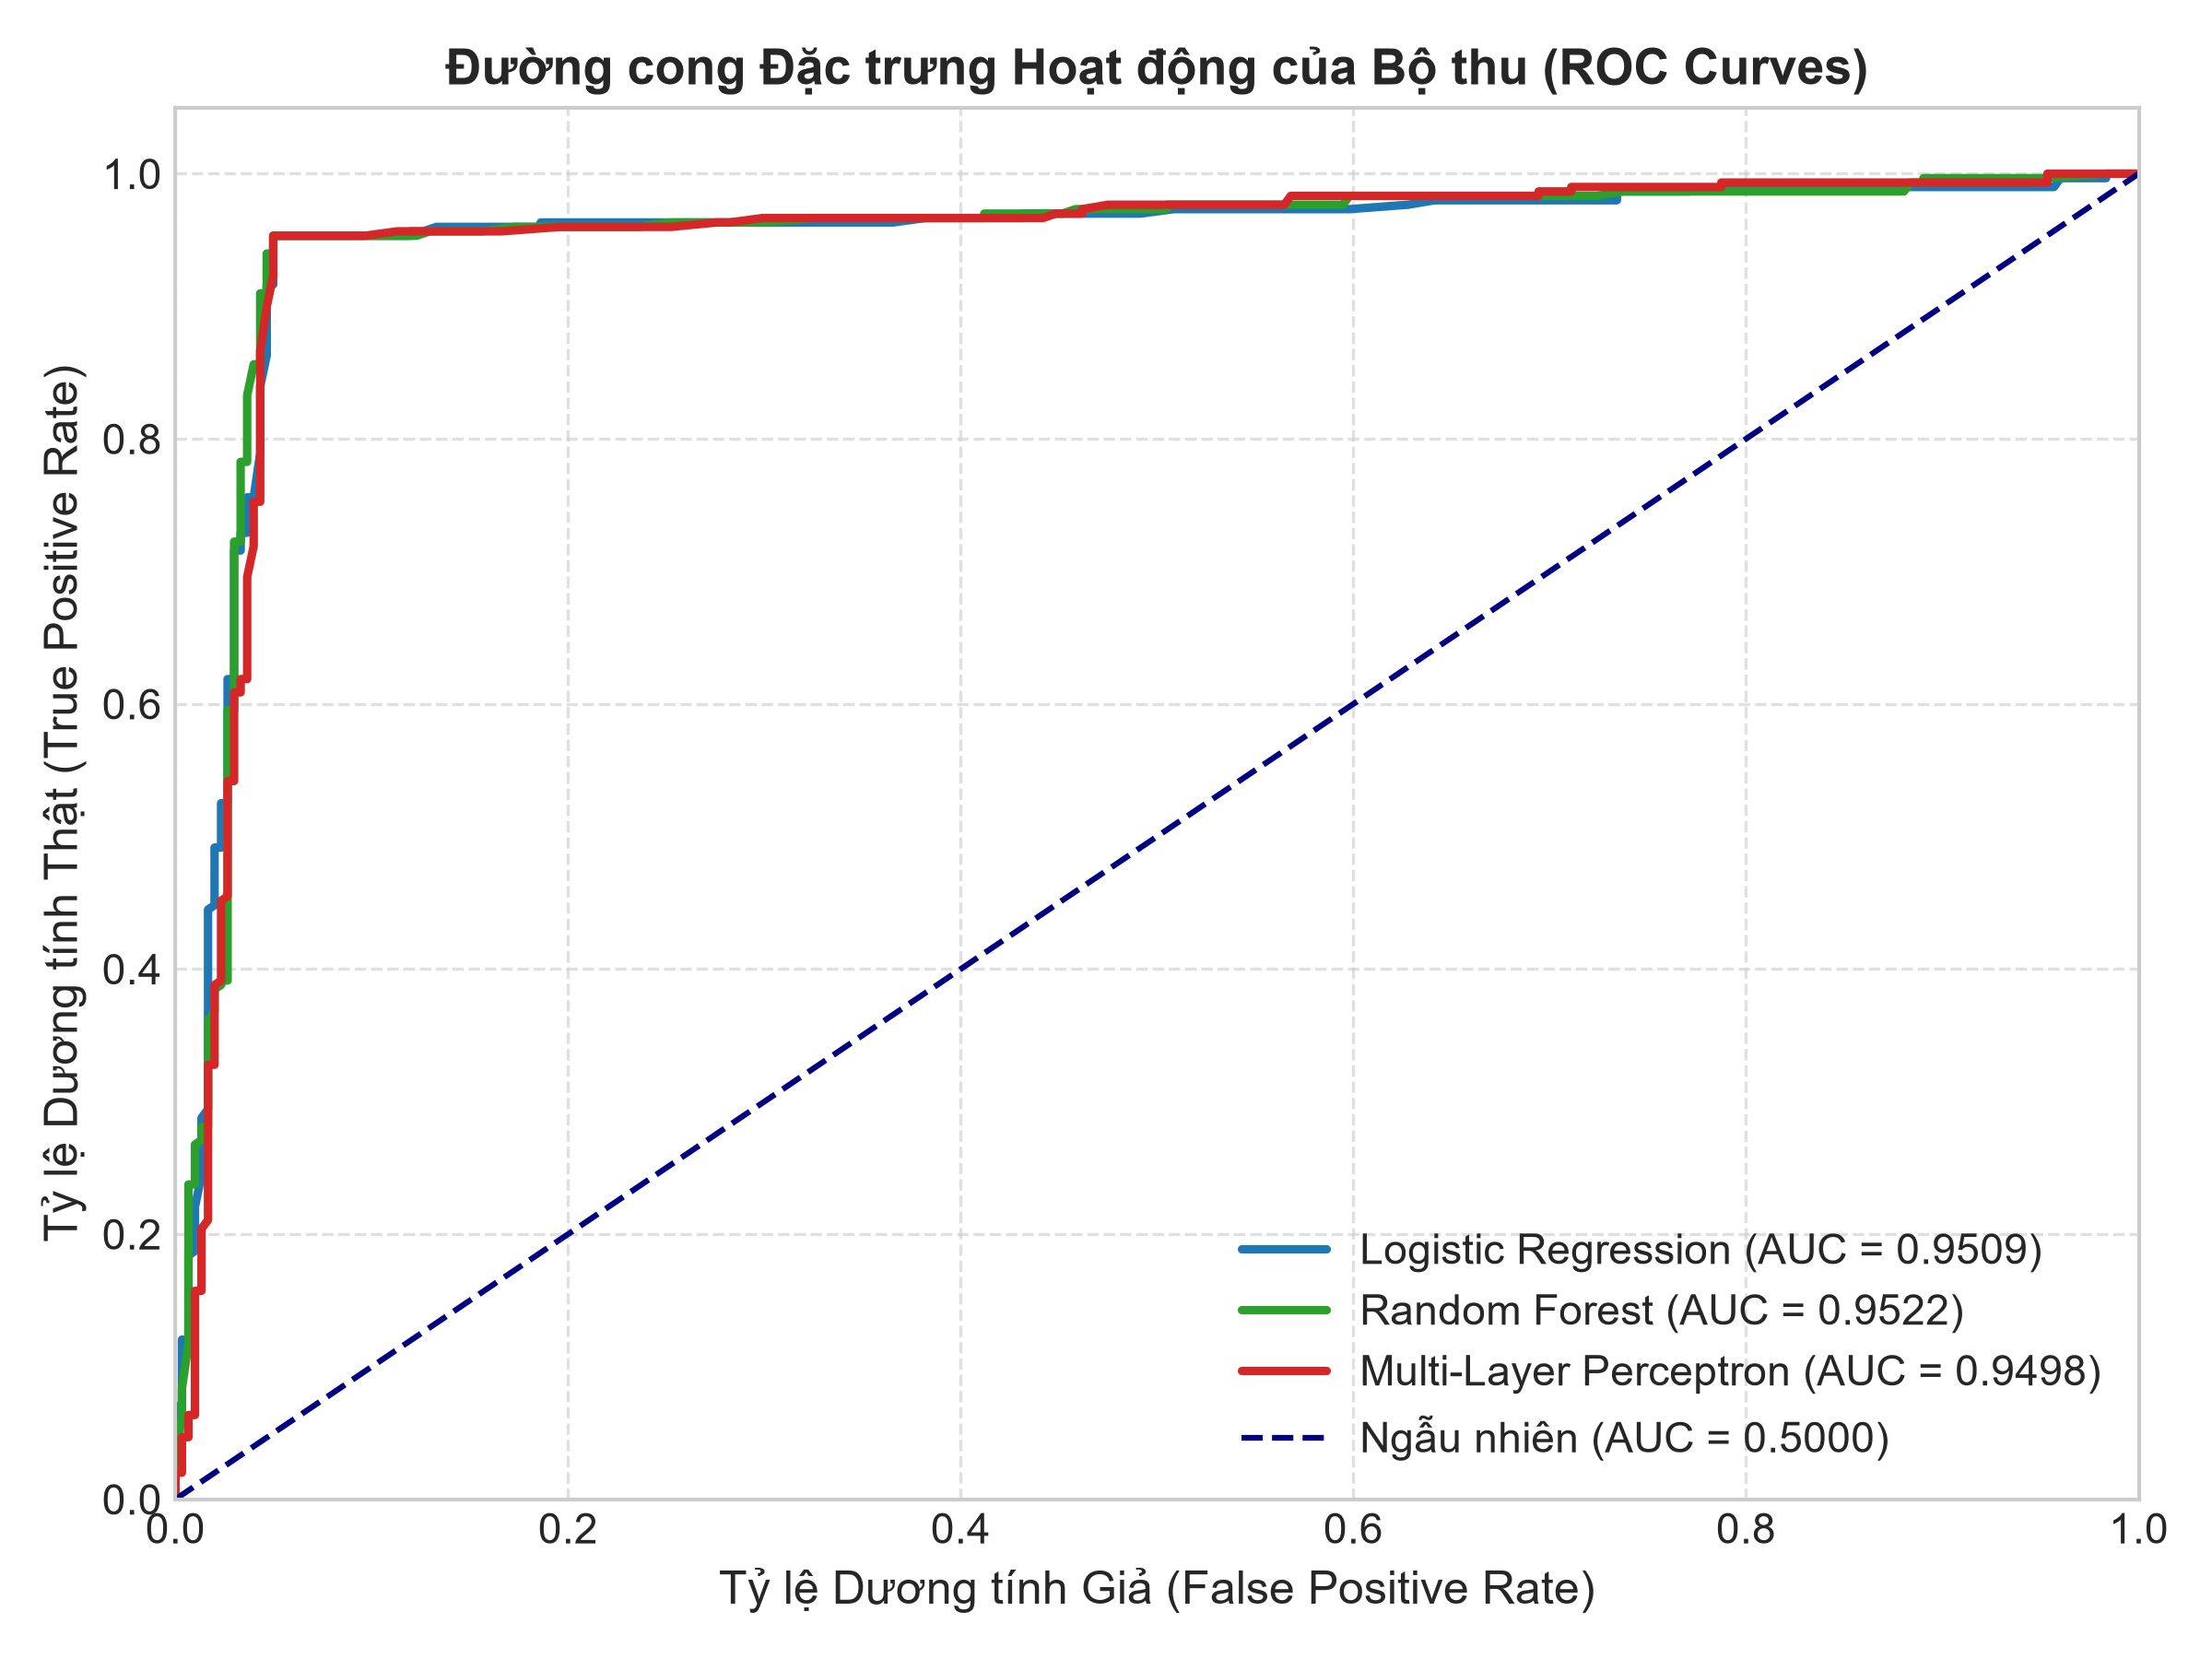

In [9]:
plot_roc_curves(eval_results, y_test, output_path="../results/figures/roc_curves.png")
Image(filename="../results/figures/roc_curves.png")


## 7. Kết Luận & Khuyến Nghị Kỹ Thuật (Conclusion & Engineering Trade-offs)
Dựa trên các bằng chứng thống kê thu được:
1. **Về độ chính xác phân loại:**
   - Cả 3 mô hình đều đạt hiệu năng phân loại rất cao trên tập dữ liệu benchmark.
   - Khoảng tin cậy 95% Bootstrap của F1-Score cho thấy sự ổn định và độ tin cậy thống kê cao.
2. **Về tốc độ và độ trễ suy luận:**
   - Mô hình **Logistic Regression** đạt tốc độ suy luận nhanh nhất với độ trễ P95 cực thấp, tiêu tốn ít tài nguyên phần cứng nhất.
   - Mô hình **Random Forest** và **Multi-Layer Perceptron** có năng lực phi tuyến tính tốt nhưng độ trễ P95 cao hơn đáng kể ($p < 0.001$).
3. **Khuyến nghị kiến trúc hệ thống:**
   - Với các hệ thống thời gian thực (Real-time Streaming, High-Throughput APIs): Nên triển khai **Logistic Regression**.
   - Với các hệ thống phân tích ngoại tuyến (Offline Batch Analytics) yêu cầu độ nhạy biên cao: Sử dụng **Multi-Layer Perceptron**.
